In [11]:
import numpy as np
from scipy.special import lambertw
import matplotlib.pyplot as plt
import pandas as pd
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif"
})
#mpl.rcParams['text.usetex'] = True

In [12]:
print((2 + lambertw(-2 * np.exp(-2)).real) )
print((1+ (lambertw(-2 * np.exp(-2)).real)/2 ))
print(-lambertw(-2 * np.exp(-2)).real*(2 + lambertw(-2 * np.exp(-2)).real))
print(1/(-lambertw(-2 * np.exp(-2)).real*(2 + lambertw(-2 * np.exp(-2)).real)))

1.5936242600400399
0.7968121300200199
0.647610237891915
1.5441386523708698


In [13]:
phi = 0.04  

# Optimal dose rate
eta_star = (2 + lambertw(-2 * np.exp(-2)).real) / phi

# Dose rate grid
eta = np.linspace(0.01, 8.0 / phi, 500)

# Fisher information per sample
I = eta**2 / (np.exp(phi * eta) - 1)

# Maximum Fisher information value
I_star = eta_star**2 / (np.exp(phi * eta_star) - 1)

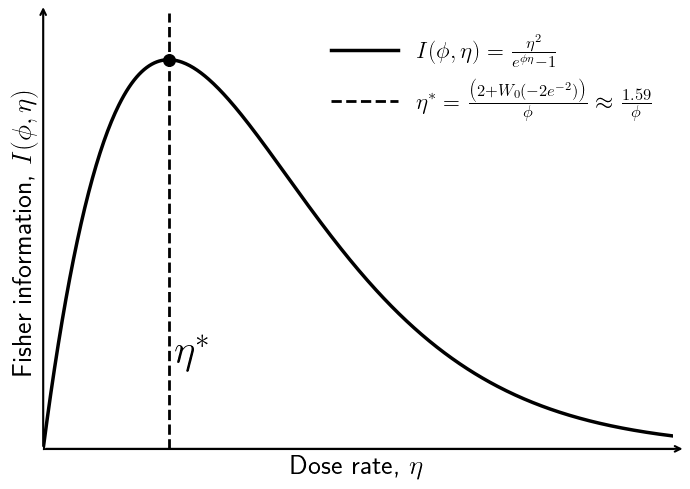

In [14]:

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    eta,
    I,
    color="black",
    lw=2.5,
    label=r"$I(\phi,\eta)=\frac{\eta^2}{e^{\phi\eta}-1}$"
)

# Optimal point: eta* ≈ 1.59 / phi
ax.axvline(
    eta_star,
    color="black",
    linestyle="--",
    lw=2,
    label=r"$\eta^* = \frac{\big(2 + W_0(-2e^{-2})\big)}{\phi} \approx \frac{1.59}{\phi}$"
)

ax.scatter(
    eta_star,
    I_star,
    color="black",
    s=70,
    zorder=5
)

# ---------------------------------------------------------------------
# Annotation
# ---------------------------------------------------------------------
ax.text(
    eta_star + 2,
    100,
    r"$\eta^\ast$",
    fontsize=30,
    ha="left",
    va="center",
)

# Keep only left and bottom axis lines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Ensure bottom and left lines remain visible
ax.spines["bottom"].set_visible(True)
ax.spines["left"].set_visible(True)

# x-axis arrow
ax.annotate(
    "",
    xy=(1.02, 0),
    xytext=(0, 0),
    xycoords="axes fraction",
    arrowprops=dict(
        arrowstyle="->",
        lw=1.5,
        color="black"
    ),
)

# y-axis arrow
ax.annotate(
    "",
    xy=(0, 1.02),
    xytext=(0, 0),
    xycoords="axes fraction",
    arrowprops=dict(
        arrowstyle="->",
        lw=1.5,
        color="black"
    ),
)
# ---------------------------------------------------------------------
# Labels
# ---------------------------------------------------------------------
ax.set_xlabel(r"Dose rate, $\eta$",fontsize=20)
ax.set_ylabel(r"Fisher information, $I(\phi,\eta)$",fontsize=20)

ax.set_xlim(0, eta.max())
ax.set_ylim(0, I.max()*1.12)

# ---------------------------------------------------------------------
# Remove tick marks and numbers
# ---------------------------------------------------------------------
ax.set_xticks([])
ax.set_yticks([])

# ---------------------------------------------------------------------
# Legend
# ---------------------------------------------------------------------
ax.legend(
    loc="upper right",
    fontsize=17,
    frameon=False,
    handlelength=2.8,
)

plt.tight_layout()
plt.savefig('figures/fisher_info.png',dpi=400)
plt.show()

1.230388408641876


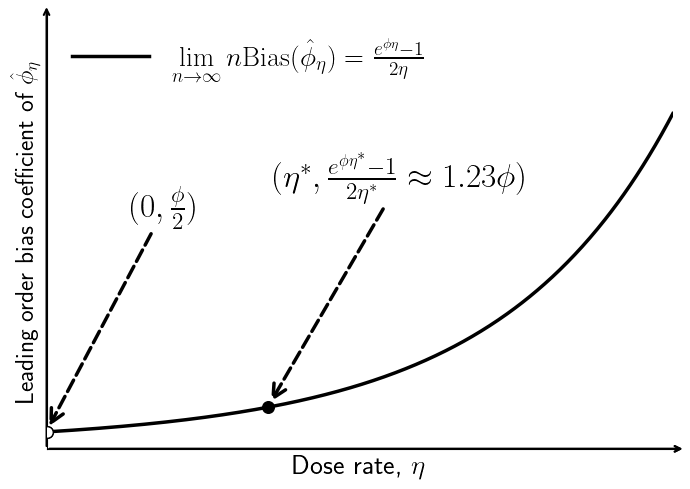

In [15]:
# ---------------------------------------------------------------------
# Parameters
# ---------------------------------------------------------------------
eta = np.linspace(0.00001, 45, 500)   # avoid eta = 0
phi = 0.1
n = 1

# Leading-order bias
bias = (np.exp(phi * eta) - 1) / (2 * eta )

# optimal dose
eta_star = (2 + lambertw(-2 * np.exp(-2)).real) / phi
bias_star = (np.exp(phi * eta_star) - 1) / (2 * eta_star )

print(bias_star/phi)
# ---------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    eta,
    bias,
    color="black",
    lw=2.5,
    label=r"$\lim\limits_{n\to\infty}n\mathrm{Bias}(\hat{\phi}_\eta)=\frac{e^{\phi\eta}-1}{2\eta }$"
)

ax.scatter(
    [0,eta_star],
    [phi/2,bias_star],
    color="black",
    s=70,
    zorder=5
)

ax.scatter(
    0,
    phi / 2,
    facecolors="white",   # or c="white"
    edgecolors="black",   # outline
    s=70,
    zorder=5
)


# ---------------------------------------------------------------------
# Labels
# ---------------------------------------------------------------------
ax.set_xlabel(r"Dose rate, $\eta$", fontsize=20)
ax.set_ylabel(r"Leading order bias coefficient of $\hat{\phi}_\eta$", fontsize=18)

ax.set_xlim(0, eta.max())
ax.set_ylim(0, bias.max()*1.3)

# Remove tick marks and numbers
ax.set_xticks([])
ax.set_yticks([])

# Legend
ax.legend(
    loc="upper left",
    fontsize=20,
    frameon=False,
    handlelength=2.8,
)

# Light grid
ax.grid(alpha=0.25)

# Keep only left and bottom spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# x-axis arrow
ax.annotate(
    "",
    xy=(1.02, 0),
    xytext=(0, 0),
    xycoords="axes fraction",
    arrowprops=dict(
        arrowstyle="->",
        lw=1.5,
        color="black"
    ),
)


# y-intercept (limit as eta -> 0)
y_intercept = phi / (2 )

# Arrow pointing to the y-intercept
ax.annotate(
    r"$(0,\frac{\phi}{2})$",
    xy=(0.1, y_intercept+0.01),          # point being annotated
    xytext=(6, y_intercept+0.6),  # position of label
    fontsize=24,
    ha="left",
    va="bottom",
    arrowprops=dict(
        arrowstyle="->",
        linestyle='--',
        lw=2.5,
        color="black"
    )
)

# Arrow pointing to the optimal dose
ax.annotate(
    r"$(\eta^*,\frac{e^{\phi\eta^*}-1}{2\eta^*}\approx1.23\phi)$",
    xy=(eta_star+0.1, bias_star+0.01),          # point being annotated
    xytext=(eta_star+0.3, bias_star+0.6),  # position of label
    fontsize=24,
    ha="left",
    va="bottom",
    arrowprops=dict(
        arrowstyle="->",
        linestyle='--',
        lw=2.5,
        color="black"
    )
)

# x-axis arrow
ax.annotate(
    "",
    xy=(1.02, 0),
    xytext=(0, 0),
    xycoords="axes fraction",
    arrowprops=dict(
        arrowstyle="->",
        lw=1.5,
        color="black"
    ),
)

# y-axis arrow
ax.annotate(
    "",
    xy=(0, 1.02),
    xytext=(0, 0),
    xycoords="axes fraction",
    arrowprops=dict(
        arrowstyle="->",
        lw=1.5,
        color="black"
    ),
)



plt.tight_layout()
plt.savefig("figures/bias.png", dpi=400)
plt.show()

In [16]:
df_exp_1 = pd.read_csv('data/Karisto_Infection_Efficiency_Zymoseptoria_Lesion_appearance_data_first_experiment_2018.txt',sep='\t')
df_exp_2 = pd.read_csv('data/Karisto_Infection_Efficiency_Zymoseptoria_Lesion_appearance_data_second_experiment_2018.txt',sep='\t')
# combine first and second experiments to a single dataframe
df_exp_1['experiment']="Experiment 1"
df_exp_2['experiment']="Experiment 2"
combined_df = pd.concat([df_exp_1,df_exp_2],ignore_index=True)
lesion_df = combined_df.groupby(['leafset','leafnumber','experiment','density','treatment'], 
                                  as_index=False).agg({
                                    'lesiontot': 'max',
                                    'leafsize': 'max'} )

In [17]:

# for calculating the MLE for infection efficiency 
from scipy.stats import binom

def likelihood(phi,X,Y,N):
    XN = X / N
    p = 1-np.exp(-phi*XN)
    log_probs = binom.logpmf(Y, N, p)
    return np.sum(log_probs)

def score_function(phi, X, Y, N):
    XN = X / N
    exp_neg = np.exp(-phi * XN)
    term1 = Y * (XN) / (1 - exp_neg)
    term2 = N* XN
    return - np.sum(term1 - term2)


def obs_info(phi, X, Y, N):
    exp_neg = np.exp(-phi * X/N)
    numerator = (X**2) * exp_neg 
    denominator = N*(1 - exp_neg)
    return np.sum(numerator / denominator)


# bisection method for root finding
def solve_score_eqn(X,Y,N,tol=1e-6,a=0.001,b=1):
    while b - a > tol:
        m = (a + b) / 2 
        if score_function(m,X,Y,N) == 0:
            return m
        elif  score_function(a,X,Y,N)  *  score_function(m,X,Y,N)  < 0:
            b = m
        else:
            a = m
    phi = (a + b)/2
    loglik = likelihood(phi,X,Y,N) 
    info = obs_info(phi,X ,Y, N)
    return phi, loglik, info


lesion_df_e1 = lesion_df[lesion_df['experiment']=="Experiment 1"]
X_1 = lesion_df_e1['leafsize']*lesion_df_e1['density']
Y_1 = lesion_df_e1['lesiontot']

lesion_df_e2 = lesion_df[lesion_df['experiment']=="Experiment 2"]
X_2 = lesion_df_e2['leafsize']*lesion_df_e2['density']
Y_2 = lesion_df_e2['lesiontot']


N_max = 70
N_min_1 = np.max(Y_1)
N_min_2 = np.max(Y_2)

logliks_e1 = []
logliks_e2 = []

phi_e1 = []
phi_e2 = []

# compute likelihoods for each N separately
for N in range(N_min_1, N_max):
    phi, loglik, _ = solve_score_eqn(X_1, Y_1, N)
    logliks_e1.append(loglik)
    phi_e1.append(phi)

for N in range(N_min_2, N_max):
    phi, loglik, _ = solve_score_eqn(X_2, Y_2, N)
    logliks_e2.append(loglik)
    phi_e2.append(phi)
    
# convert to probabilities
logliks_e1 = np.array(logliks_e1)
logliks_e2 = np.array(logliks_e2)

probs_e1 = np.exp(logliks_e1 - np.max(logliks_e1))
probs_e1 /= probs_e1.sum()

probs_e2 = np.exp(logliks_e2 - np.max(logliks_e2))
probs_e2 /= probs_e2.sum()

# MLE indices
N1_vals = np.arange(N_min_1, N_max)
N2_vals = np.arange(N_min_2, N_max)
N1_mle = N1_vals[np.argmax(logliks_e1)]
N2_mle = N2_vals[np.argmax(logliks_e2)]

phi_mle_e1 =  phi_e1[np.argmax(logliks_e1)]
phi_mle_e2 =  phi_e2[np.argmax(logliks_e2)]

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import numpy.ma as ma
from matplotlib import cm
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from tqdm import tqdm


# colormaps with transparency for masked values
cmapR = cm.get_cmap("Reds").copy()
cmapR.set_bad(color=(1, 1, 1, 0))  # fully transparent

cmapB = cm.get_cmap("Blues").copy()
cmapB.set_bad(color=(1, 1, 1, 0))  # fully transparent

# grid for phi and kappa
phi_vals = np.linspace(0.035, 0.05, 500)
kappa_vals = np.arange(20, 80)

# storage
heat_1 = np.zeros((len(kappa_vals), len(phi_vals)))
heat_2 = np.zeros((len(kappa_vals), len(phi_vals)))

# fill heatmaps
for i, k in enumerate(tqdm(kappa_vals)):
    heat_1[i, :] = np.array([likelihood(phi, X_1, Y_1, k) for phi in phi_vals])
    heat_2[i, :] = np.array([likelihood(phi, X_2, Y_2, k) for phi in phi_vals])

# relative log-likelihoods
heat_1 -= heat_1.max()
heat_2 -= heat_2.max()


phi_vals = phi_vals*100

/tmp/ipykernel_228728/1018378371.py:11: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmapR = cm.get_cmap("Reds").copy()
/tmp/ipykernel_228728/1018378371.py:14: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmapB = cm.get_cmap("Blues").copy()
100%|██████████████████████████████████████████████████████████████████████████████████████████████| 60/60 [00:08<00:00,  6.71it/s]


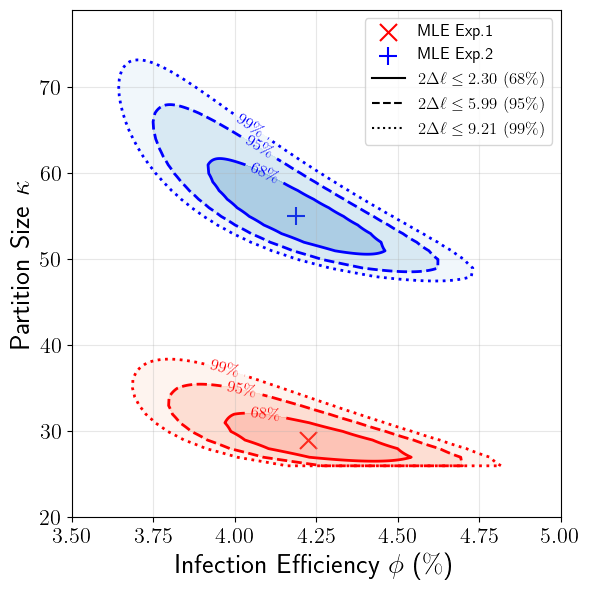

In [26]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import numpy as np
import matplotlib as mpl


fig, ax = plt.subplots(figsize=(6,6))
plt.grid(alpha=0.3)

# ---- clip likelihoods ----
heat_1 = np.clip(heat_1, -20000, None)
heat_2 = np.clip(heat_2, -20000, None)

ax.set_xlabel(r"Infection Efficiency $\phi$ ($\%$)", fontsize=20)
ax.set_ylabel(r"Partition Size $\kappa$", fontsize=20)

# ---- correct MLE extraction ----
idx1 = np.unravel_index(np.argmax(heat_1), heat_1.shape)
kappa_mle_1 = kappa_vals[idx1[0]]
phi_mle_1   = phi_vals[idx1[1]]

idx2 = np.unravel_index(np.argmax(heat_2), heat_2.shape)
kappa_mle_2 = kappa_vals[idx2[0]]
phi_mle_2   = phi_vals[idx2[1]]

# ---- plot MLE markers ----
ax.scatter(phi_mle_1, kappa_mle_1, marker='x', s=150, color='red', label='MLE Exp.1')
ax.scatter(phi_mle_2, kappa_mle_2, marker='+', s=150, color='blue', label='MLE Exp.2')

# ---- meshgrid ----
PHI, KAPPA = np.meshgrid(phi_vals, kappa_vals)

# ---- likelihood thresholds (Delta logL for 2 params) ----
levels = [-4.61, -3.00, -1.15]   # 99%, 95%, 68%  # 99%, 95%, 68%
linestyles = ['dotted','dashed','solid']  # match levels

# ---- contours and shaded interiors ----
# Fill between contours for shading
colors = ['#fee5d9',  # very light pinkish-orange
          '#fcae91',  # medium warm red
          '#fb6a4a'] # red shades for Exp1
c1f = ax.contourf(PHI, KAPPA, heat_1, levels=levels + [0], colors=colors, alpha=0.4, extend='max')

colors2 = ['#deebf7', '#9ecae1', '#3182bd']  # blue shades for Exp2
c2f = ax.contourf(PHI, KAPPA, heat_2, levels=levels + [0], colors=colors2, alpha=0.4, extend='max')


# ---- label contours ----
x_min, x_max = phi_vals.min(), phi_vals.max()
y_min, y_max = kappa_vals.min(), kappa_vals.max()

manual_c1 = [
    ((x_min + x_max)/2, y_max - 0.02*(y_max - y_min)),  # 68%
    ((x_min + x_max)/2, y_max - 0.06*(y_max - y_min)),  # 95%
    ((x_min + x_max)/2, y_max - 0.10*(y_max - y_min))   # 99%
]

manual_c2 = [
    ((x_min + x_max)/2, y_max - 0.03*(y_max - y_min)),  # 68%
    ((x_min + x_max)/2, y_max - 0.07*(y_max - y_min)),  # 95%
    ((x_min + x_max)/2, y_max - 0.11*(y_max - y_min))   # 99%
]

styles = [ 'dotted', 'dashed','solid']
fmt = {
    -1.15: r"$68\%$",
    -3.00: r"$95\%$",
    -4.61: r"$99\%$"
}

# single-level contour for heat_1
for level, pos,style in zip(levels, manual_c1,styles):
    cs = ax.contour(PHI, KAPPA, heat_1, levels=[level], colors='red', linestyles=style, linewidths=2)
    ax.clabel(cs, fmt={level: fmt[level]}, manual=[pos], inline=True, fontsize=12)

# single-level contour for heat_2
for level, pos,style in zip(levels, manual_c2,styles):
    cs = ax.contour(PHI, KAPPA, heat_2, levels=[level], colors='blue', linestyles=style, linewidths=2)
    ax.clabel(cs, fmt={level: fmt[level]}, manual=[pos], inline=True, fontsize=12,)


# ---- legend ----


ax.plot([], [], color='black', linestyle='solid',
        label=r'$2\Delta\ell \leq 2.30$ $(68\%)$')
ax.plot([], [], color='black', linestyle='dashed',
        label=r'$2\Delta\ell \leq 5.99$ $(95\%)$')
ax.plot([], [], color='black', linestyle='dotted',
        label=r'$2\Delta\ell \leq 9.21$ $(99\%)$')

ax.legend( loc='upper right',fontsize=12)

ax.tick_params(axis='x', labelsize=16)
ax.tick_params(axis='y', labelsize=16)



plt.tight_layout()
plt.savefig("figures/ll_heatmap.png", dpi=300)
plt.show()

Exp. 1: phi_hat = 4.2244%
        95% CI = [3.8908%, 4.6152%]
Exp. 2: phi_hat = 4.1884%
        95% CI = [3.8397%, 4.5371%]


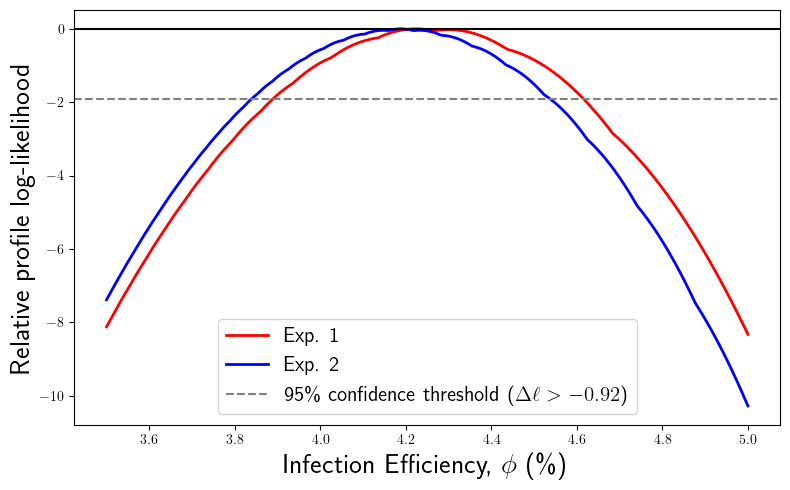

In [10]:
# Profile log-likelihood for phi
profile_1 = np.max(heat_1, axis=0)
profile_2 = np.max(heat_2, axis=0)

# 95% confidence threshold
threshold = -1.92

# Find confidence intervals
mask_1 = profile_1 >= threshold
mask_2 = profile_2 >= threshold

# phi values within the 95% confidence region
phi_ci_1 = phi_vals[mask_1] 
phi_ci_2 = phi_vals[mask_2]

# Print confidence intervals
print(f"Exp. 1: phi_hat = {phi_vals[np.argmax(profile_1)]:.4f}%")
print(f"        95% CI = [{phi_ci_1.min():.4f}%, {phi_ci_1.max():.4f}%]")

print(f"Exp. 2: phi_hat = {phi_vals[np.argmax(profile_2)]:.4f}%")
print(f"        95% CI = [{phi_ci_2.min():.4f}%, {phi_ci_2.max():.4f}%]")


# Plot
plt.figure(figsize=(8, 5))

plt.plot(phi_vals, profile_1,'-r',label="Exp. 1", linewidth=2)
plt.plot(phi_vals, profile_2,'-b', label="Exp. 2", linewidth=2)

plt.axhline(-1.92, color="gray", linestyle="--",
            label="95\% confidence threshold ($\Delta\ell > -0.92$)")

plt.axhline(0, color="black", linestyle="-")


plt.xlabel(r"Infection Efficiency, $\phi$ (\%)",fontsize=20)
plt.ylabel("Relative profile log-likelihood",fontsize=20)
plt.legend(fontsize=15)
plt.tight_layout()
plt.savefig('figures/CI.png',dpi=300)
plt.show()

100%|████| 3000/3000 [00:00<00:00, 32628.73it/s]


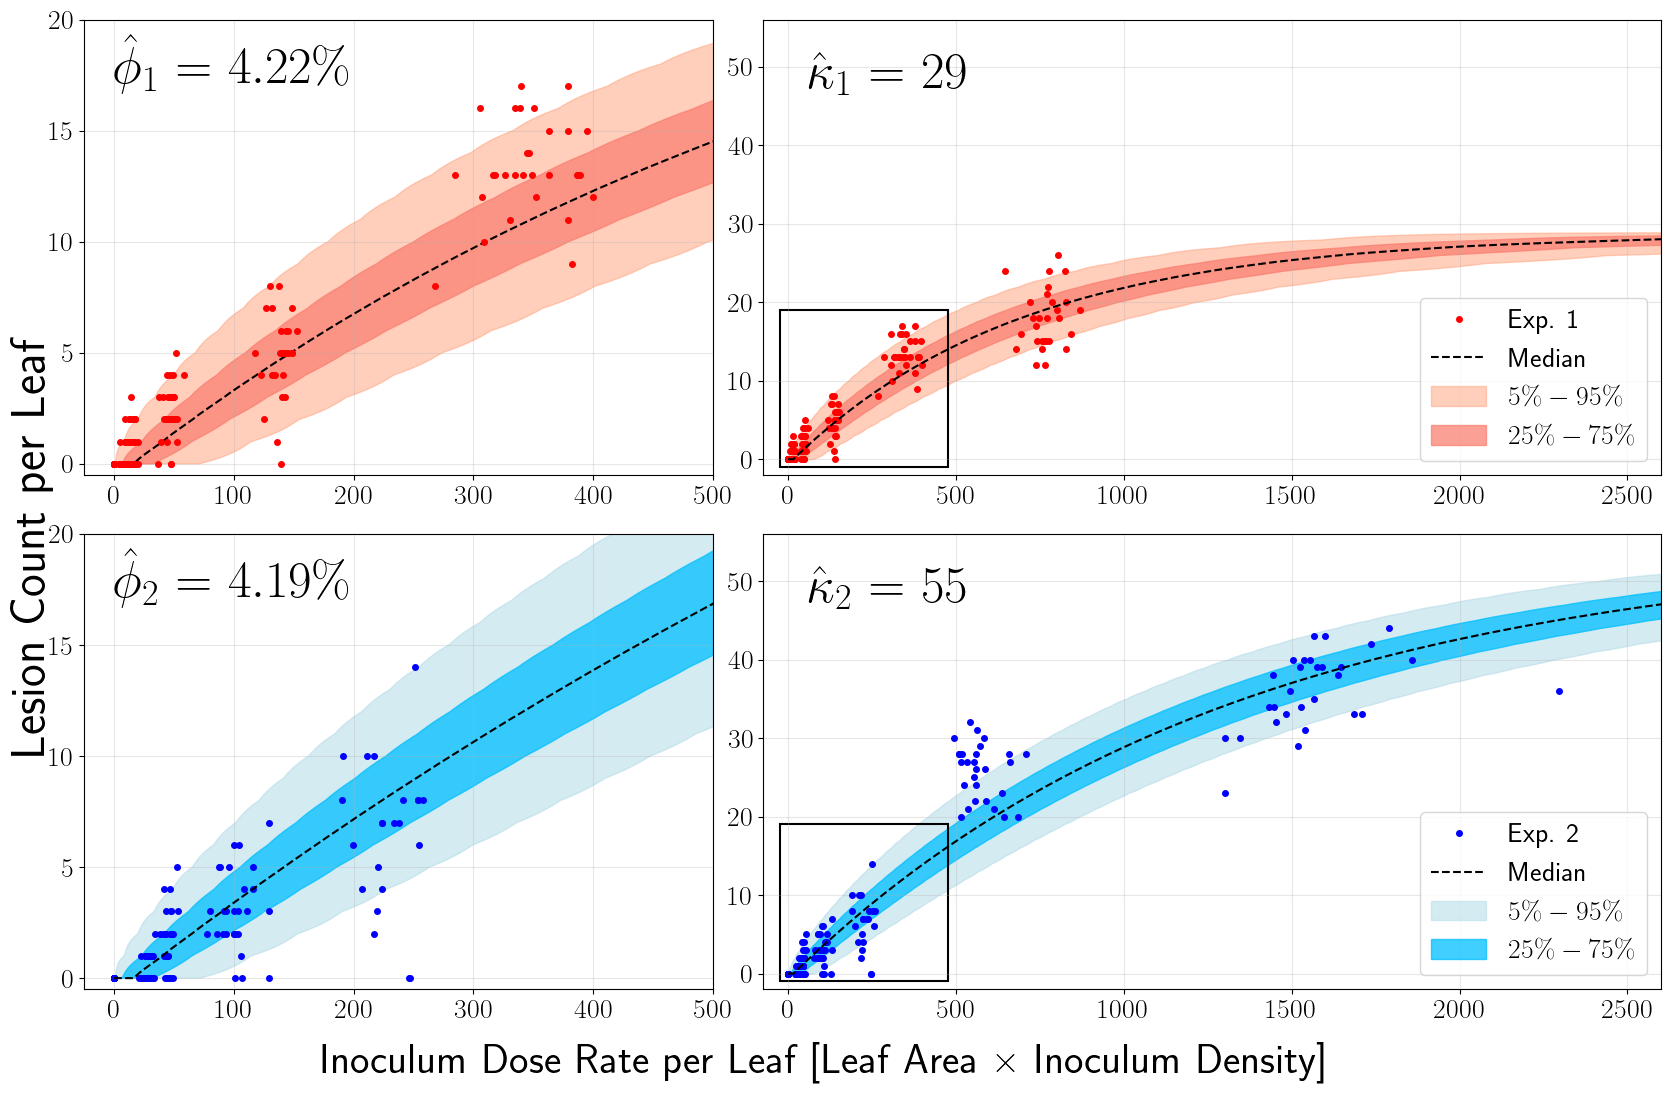

In [12]:


spore_number_range = np.arange(0,3000)
lesion_number_range = np.arange(0,N+1)

max_lesion_df = lesion_df

max_lesion_df['expected_spore_number'] = max_lesion_df['leafsize'] * max_lesion_df['density']


import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 2, figsize=(17, 11), sharey=False, gridspec_kw={'width_ratios': [1.4, 2]})

pmfs = []
for spore_num in tqdm(spore_number_range):
    
    p = 1-np.exp(-phi_mle_e1*spore_num/N1_mle)
    pmf = binom.pmf(lesion_number_range,N1_mle,p)
    pmfs.append(pmf)

quantiles = [0.05,0.25,0.5,0.75,0.95]
means = [] 
quantile_values = []
for pmf in pmfs:
    cdf = np.cumsum(pmf)
    mean = np.sum(pmf*lesion_number_range)
    means.append(mean)
    quantile_values.append(np.interp(quantiles, cdf ,lesion_number_range))

quantile_values = np.array(quantile_values)

axs[0,0].plot(spore_number_range, quantile_values[:,2],'--', color='black')
axs[0,0].fill_between(spore_number_range, quantile_values[:,0], quantile_values[:,-1], color='lightsalmon', alpha=0.5)
axs[0,0].fill_between(spore_number_range, quantile_values[:,1], quantile_values[:,-2], color='salmon', alpha=0.75)


axs[0,0].plot(
    max_lesion_df[max_lesion_df['experiment'] == "Experiment 1"]['expected_spore_number'],
    max_lesion_df[max_lesion_df['experiment'] == "Experiment 1"]['lesiontot'],
    '.r', markersize=8
)


axs[0,0].set_xlim(-25, 500)
axs[0,0].set_ylim(-0.5, 20)
#axs[1].set_xlabel('Spores (Zoomed)')
axs[0,0].grid(alpha=0.3)

axs[0,0].set_yticks([0, 5, 10, 15, 20])
axs[0,0].tick_params(axis='x', labelsize=20)
axs[0,0].tick_params(axis='y', labelsize=20)


# RIGHT PLOT (Full view)
#axs[0].plot(spore_number_range, means, color='black', label='Mean')
axs[0,1].plot(
    max_lesion_df[max_lesion_df['experiment'] == "Experiment 1"]['expected_spore_number'],
    max_lesion_df[max_lesion_df['experiment'] == "Experiment 1"]['lesiontot'],
    '.r', label='Exp. 1', markersize=8
)
axs[0,1].plot(spore_number_range, quantile_values[:,2],'--', color='black', label='Median')
axs[0,1].fill_between(spore_number_range, quantile_values[:,0], quantile_values[:,-1], color='lightsalmon', alpha=0.5, label='$5\%-95\%$')
axs[0,1].fill_between(spore_number_range, quantile_values[:,1], quantile_values[:,-2], color='salmon', alpha=0.75, label='$25\%-75\%$')




# Dashed rectangle on full plot
box = plt.Rectangle((-25, -1), 500, 20,  linewidth=1.5, edgecolor='black', facecolor='none', linestyle='-')
axs[0,1].add_patch(box )
#textstr = "$\hat{{\phi}}_{{\text{{MLE}}}}$ "+ f"{phi_mle_e1 * 100:.1f}" + "\% (Exp. 1)"

textstr = "$\hat{\phi}_1$"+ f" = ${phi_mle_e1 * 100:.2f}$" + "$\%$"


#props = dict(boxstyle='round', facecolor='white', alpha=0.5)
axs[0,0].text(100, 18, textstr, fontsize=37,
            verticalalignment='center', horizontalalignment='center')

#textstr = f"Partition Size (MLE) $\sim {N1_mle}$"
textstr =  "$\hat{\kappa}_1$"+ f" = ${N1_mle}$"

#textstr = f"$\hat{\phi}_{\text{MLE}} (MLE) = {phi_e1 *100:.2g} %\n"
#props = dict(boxstyle='round', facecolor='white', alpha=0.5)
axs[0,1].text(300, 49, textstr, fontsize=37,
            verticalalignment='center', horizontalalignment='center')




#axs[0].set_xlabel('Expected Number of Spores (per Leaf)\n[Leaf Area × Spore Density]')
axs[0,1].legend(loc='lower right',fontsize=20)
axs[0,1].set_xlim(-75, 2600)
axs[0,1].set_ylim(-2, N2_mle+1)
axs[0,1].grid(alpha=0.3)
axs[0,1].tick_params(axis='x', labelsize=20)
axs[0,1].tick_params(axis='y', labelsize=20)



#axs[1].plot(spore_number_range, quantile_values[:,2],'--', color='black')
#axs[1].fill_between(spore_number_range, quantile_values[:,0], quantile_values[:,-1], color='red', alpha=0.5)
#axs[1].fill_between(spore_number_range, quantile_values[:,1], quantile_values[:,-2], color='red', alpha=0.75)

pmfs = []
for spore_num in tqdm(spore_number_range):
    
    p = 1-np.exp(-phi_mle_e2*spore_num/N2_mle)
    pmf = binom.pmf(lesion_number_range,N2_mle,p)
    pmfs.append(pmf)


quantiles = [0.05,0.25,0.5,0.75,0.95]
means = [] 
quantile_values = []
for pmf in pmfs:
    cdf = np.cumsum(pmf)
    mean = np.sum(pmf*lesion_number_range)
    means.append(mean)
    quantile_values.append(np.interp(quantiles, cdf ,lesion_number_range))

quantile_values = np.array(quantile_values)

axs[1,0].plot(
    max_lesion_df[max_lesion_df['experiment'] == "Experiment 2"]['expected_spore_number'],
    max_lesion_df[max_lesion_df['experiment'] == "Experiment 2"]['lesiontot'],
    '.b', markersize=8
)
axs[1,0].plot(spore_number_range, quantile_values[:,2],'--', color='black')
axs[1,0].fill_between(spore_number_range, quantile_values[:,0], quantile_values[:,-1], color='lightblue', alpha=0.5)
axs[1,0].fill_between(spore_number_range, quantile_values[:,1], quantile_values[:,-2], color='deepskyblue', alpha=0.75)



axs[1,0].set_xlim(-25, 500)
axs[1,0].set_ylim(-0.5, 20)
#axs[1].set_xlabel('Spores (Zoomed)')
axs[1,0].grid(alpha=0.3)
axs[1,0].tick_params(axis='x', labelsize=20)
axs[1,0].tick_params(axis='y', labelsize=20)

# RIGHT PLOT (Full view)
#axs[0].plot(spore_number_range, means, color='black', label='Mean')
axs[1,1].plot(
    max_lesion_df[max_lesion_df['experiment'] == "Experiment 2"]['expected_spore_number'],
    max_lesion_df[max_lesion_df['experiment'] == "Experiment 2"]['lesiontot'],
    '.b', label='Exp. 2', markersize=8
)
axs[1,1].plot(spore_number_range, quantile_values[:,2],'--', color='black', label='Median')
axs[1,1].fill_between(spore_number_range, quantile_values[:,0], quantile_values[:,-1], color='lightblue', alpha=0.5, label='$5\%-95\%$')
axs[1,1].fill_between(spore_number_range, quantile_values[:,1], quantile_values[:,-2], color='deepskyblue', alpha=0.75, label='$25\%-75\%$')

axs[1,1].tick_params(axis='x', labelsize=20)
axs[1,1].tick_params(axis='y', labelsize=20)


# Dashed rectangle on full plot
box = plt.Rectangle((-25, -1), 500, 20,  linewidth=1.5, edgecolor='black', facecolor='none', linestyle='-')
axs[1,1].add_patch(box )
#textstr = "$\hat{\phi}_{\text{{MLE}}$ "+ f"${phi_mle_e2 * 100:.1f}$" + "\% (Exp. 2)"
#textstr = r"$\hat{\phi}_{\mathrm{MLE}} = " + f"{phi_mle_e2 * 100:.1f}" + r"\% (\text{Exp.~2})$"
textstr = "$\hat{\phi}_2$"+ f" = ${phi_mle_e2 * 100:.2f}$" + "$\%$"

#props = dict(boxstyle='round', facecolor='white', alpha=0.5)
axs[1,0].text(100, 18, textstr, fontsize=37,
            verticalalignment='center', horizontalalignment='center')
textstr =  "$\hat{\kappa}_2$"+ f" = ${N2_mle}$"
#textstr = f"$\\hat{{\\phi}}_{{\\mathrm{{MLE}}}} = {phi_mle_e2*100:.1f}\\%$ (Exp.~2)"


#textstr = f"$\hat{\phi}_{\text{MLE}} (MLE) = {phi_e1 *100:.2g} %\n"
#props = dict(boxstyle='round', facecolor='white', alpha=0.5)
axs[1,1].text(300, 49, textstr, fontsize=37,
            verticalalignment='center', horizontalalignment='center')


#axs[0].set_xlabel('Expected Number of Spores (per Leaf)\n[Leaf Area × Spore Density]')
axs[1,1].legend(loc='lower right',fontsize=20)
axs[1,1].set_xlim(-75, 2600)
axs[1,1].set_ylim(-2, N2_mle+1)
axs[1,1].grid(alpha=0.3)


axs[1,0].set_yticks([0, 5, 10, 15, 20])
fig.supxlabel("Inoculum Dose Rate per Leaf [Leaf Area × Inoculum Density]", fontsize=30)
fig.supylabel('Lesion Count per Leaf',fontsize=35)

plt.tight_layout()
plt.savefig("figures/binom_fit.png", dpi=300)
plt.show()

In [31]:
df_exp_1 = pd.read_csv('data/Karisto_Infection_Efficiency_Zymoseptoria_Lesion_appearance_data_first_experiment_2018.txt',sep='\t')
df_exp_2 = pd.read_csv('data/Karisto_Infection_Efficiency_Zymoseptoria_Lesion_appearance_data_second_experiment_2018.txt',sep='\t')
# combine first and second experiments to a single dataframe
df_exp_1['experiment']="Experiment 1"
df_exp_2['experiment']="Experiment 2"
combined_df = pd.concat([df_exp_1,df_exp_2],ignore_index=True)
lesion_df = combined_df.groupby(['leafset','leafnumber','experiment','density','treatment'], 
                                  as_index=False).agg({
                                    'lesiontot': 'max',
                                    'leafsize': 'max'} )

lesion_df['dose'] = lesion_df['leafsize']*lesion_df['density']


lesion_df_e1 = lesion_df[lesion_df['experiment']=="Experiment 1"]
lesion_df_e1 = lesion_df_e1[lesion_df_e1['dose']<200]
X_1 = lesion_df_e1['leafsize']*lesion_df_e1['density']
Y_1 = lesion_df_e1['lesiontot']

lesion_df_e2 = lesion_df[lesion_df['experiment']=="Experiment 2"]
lesion_df_e2 = lesion_df_e2[lesion_df_e2['dose']<450]
X_2 = lesion_df_e2['leafsize']*lesion_df_e2['density']
Y_2 = lesion_df_e2['lesiontot']


In [32]:
# -------------------------------------------------------
# Calculate estimates and 95% confidence intervals
# -------------------------------------------------------

# Partition approximation
partition_est_1 = phi_vals[np.argmax(profile_1)]/100
partition_est_2 = phi_vals[np.argmax(profile_2)]/100

partition_ci_1 = [phi_ci_1.min() / 100, phi_ci_1.max() / 100]
partition_ci_2 = [phi_ci_2.min() / 100, phi_ci_2.max() / 100]


# OLS Exp. 1
ols_est_1 = np.sum(X_1 * Y_1) / np.sum(X_1**2)
ols_sd_1 = np.sqrt(
    ols_est_1 * np.sum(X_1**3) /
    (np.sum(X_1**2)**2)
)

ols_ci_1 = [
    ols_est_1 - 1.96 * ols_sd_1,
    ols_est_1 + 1.96 * ols_sd_1
]


# OLS Exp. 2
ols_est_2 = np.sum(X_2 * Y_2) / np.sum(X_2**2)
ols_sd_2 = np.sqrt(
    ols_est_2 * np.sum(X_2**3) /
    (np.sum(X_2**2)**2)
)

ols_ci_2 = [
    ols_est_2 - 1.96 * ols_sd_2,
    ols_est_2 + 1.96 * ols_sd_2
]


# MLE Exp. 1
mle_est_1 = np.sum(Y_1) / np.sum(X_1)
mle_sd_1 = np.sqrt(
    mle_est_1 / np.sum(X_1)
)

mle_ci_1 = [
    mle_est_1 - 1.96 * mle_sd_1,
    mle_est_1 + 1.96 * mle_sd_1
]


# MLE Exp. 2
mle_est_2 = np.sum(Y_2) / np.sum(X_2)
mle_sd_2 = np.sqrt(
    mle_est_2 / np.sum(X_2)
)

mle_ci_2 = [
    mle_est_2 - 1.96 * mle_sd_2,
    mle_est_2 + 1.96 * mle_sd_2
]


# -------------------------------------------------------
# Put everything into arrays
# -------------------------------------------------------

estimates = np.array([
    partition_est_1,
    ols_est_1,
    mle_est_1,
    partition_est_2,
    ols_est_2,
    mle_est_2
]) * 100

lower = np.array([
    partition_ci_1[0],
    ols_ci_1[0],
    mle_ci_1[0],
    partition_ci_2[0],
    ols_ci_2[0],
    mle_ci_2[0]
]) * 100

upper = np.array([
    partition_ci_1[1],
    ols_ci_1[1],
    mle_ci_1[1],
    partition_ci_2[1],
    ols_ci_2[1],
    mle_ci_2[1]
]) * 100


In [35]:
# -------------------------------------------------------
# Nicely formatted results
# -------------------------------------------------------

print("\n" + "=" * 72)
print("Parameter Estimates and 95% Confidence Intervals")
print("=" * 72)

print(f"{'Method':<25} {'Experiment':<12} {'Estimate':>12} {'95% CI':>22}")
print("-" * 72)


print(
    f"{'MLE (Poisson)':<25} "
    f"{'Exp. 1':<12} "
    f"{estimates[2]:>12.3f} "
    f"[{lower[2]:.3f}, {upper[2]:.3f}]"
)

print(
    f"{'OLS (Poisson)':<25} "
    f"{'Exp. 1':<12} "
    f"{estimates[1]:>12.3f} "
    f"[{lower[1]:.3f}, {upper[1]:.3f}]"
)



print(
    f"{'Partition approximation':<25} "
    f"{'Exp. 1':<12} "
    f"{estimates[0]:>12.3f} "
    f"[{lower[0]:.3f}, {upper[0]:.3f}]"
)


print("-" * 72)


print(
    f"{'MLE (Poisson)':<25} "
    f"{'Exp. 2':<12} "
    f"{estimates[5]:>12.3f} "
    f"[{lower[5]:.3f}, {upper[5]:.3f}]"
)

print(
    f"{'OLS (Poisson)':<25} "
    f"{'Exp. 2':<12} "
    f"{estimates[4]:>12.3f} "
    f"[{lower[4]:.3f}, {upper[4]:.3f}]"
)

print(
    f"{'Partition approximation':<25} "
    f"{'Exp. 2':<12} "
    f"{estimates[3]:>12.3f} "
    f"[{lower[3]:.3f}, {upper[3]:.3f}]"
)


print("=" * 72)
print("CIs: 95% confidence intervals")
print("Partition approximation: profile-likelihood CI")
print("OLS / MLE: Wald CI")
print("=" * 72)


Parameter Estimates and 95% Confidence Intervals
Method                    Experiment       Estimate                 95% CI
------------------------------------------------------------------------
MLE (Poisson)             Exp. 1              4.047 [3.524, 4.570]
OLS (Poisson)             Exp. 1              3.694 [3.134, 4.253]
Partition approximation   Exp. 1              4.224 [3.891, 4.615]
------------------------------------------------------------------------
MLE (Poisson)             Exp. 2              2.901 [2.566, 3.236]
OLS (Poisson)             Exp. 2              2.852 [2.476, 3.228]
Partition approximation   Exp. 2              4.188 [3.840, 4.537]
CIs: 95% confidence intervals
Partition approximation: profile-likelihood CI
OLS / MLE: Wald CI


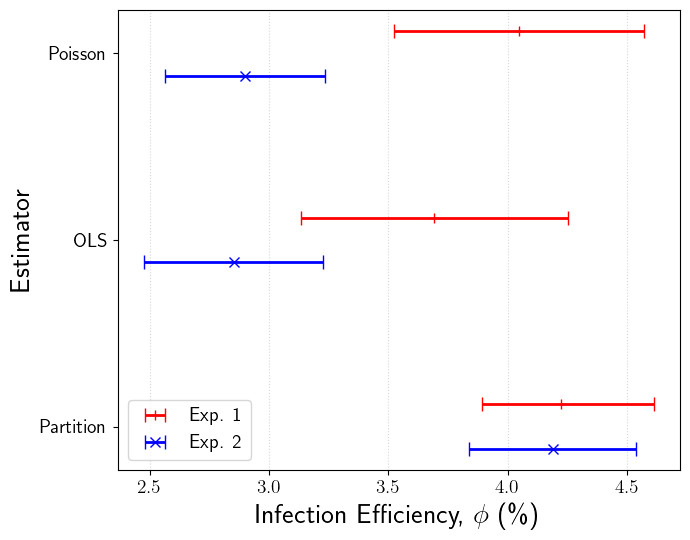

In [22]:
# -------------------------------------------------------
# Plot: two experiments on the same estimator rows
# -------------------------------------------------------

labels = [
    "Partition",
    "OLS",
    "Poisson"
]
xerr = np.array([
    estimates - lower,
    upper - estimates
])

# y positions
y = np.arange(3)

# Small vertical offset so the two experiments don't overlap
offset = 0.12

fig, ax = plt.subplots(figsize=(7, 5.5))

# -------------------------------------------------------
# Experiment 1
# -------------------------------------------------------

ax.errorbar(
    estimates[:3],
    y + offset,
    xerr=xerr[:, :3],
    fmt='+',
    color='red',
    ecolor='red',
    capsize=5,
    markersize=7,
    linewidth=2,
    label="Exp. 1"
)

# -------------------------------------------------------
# Experiment 2
# -------------------------------------------------------

ax.errorbar(
    estimates[3:],
    y - offset,
    xerr=xerr[:, 3:],
    fmt='x',
    color='blue',
    ecolor='blue',
    capsize=5,
    markersize=7,
    linewidth=2,
    label="Exp. 2"
)

# -------------------------------------------------------
# Formatting
# -------------------------------------------------------

ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=14)
ax.set_yticks(y)

ax.tick_params(axis='x', labelsize=14)


ax.set_xlabel(
    r"Infection Efficiency, $\phi$ (\%)",
    fontsize=20
)

ax.set_ylabel(
    "Estimator",
    fontsize=20
)

ax.legend(
    fontsize=14,
    loc='lower left'
)
ax.grid(
    axis='x',
    
    linestyle=':',
    alpha=0.5
)

plt.tight_layout()
plt.savefig('figures/intervals.png',dpi=400)
plt.show()